# Exercises XP: Text Preprocessing, NER, POS, and Word2Vec

## What you will learn
- Clean and normalize raw reviews with tokenization, stopword removal, and lemmatization.
- Extract linguistic features with named entity recognition (NER) and part-of-speech (POS) tagging.
- Train a simple Word2Vec model and interpret its vector dimensions.
- Visualize word embeddings to reason about semantic neighborhoods.

## What you will create
- A `preprocess_text` function that lowercases, strips punctuation, removes stopwords, and lemmatizes.
- `perform_ner` and `perform_pos_tagging` helpers to analyze raw vs cleaned text.
- A Word2Vec model plus a helper to plot embeddings for inspection.

## Setup · install libraries

In [1]:
%pip install --quiet spacy nltk gensim matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.

In [2]:
import nltk
from spacy.cli import download as spacy_download
import spacy

resources = ["punkt", "punkt_tab", "wordnet", "omw-1.4", "stopwords",
             "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng",
             "tagsets", "tagsets_json"]
for res in resources:
    nltk.download(res, quiet=True)

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy_download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")
print("spaCy pipeline:", nlp.pipe_names)

spaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## Exercise 1 · Explore text preprocessing, NER, and POS tags

In [3]:
import pandas as pd
pd.set_option("display.max_colwidth", 120)

data = {
    'Review': [
        "At McDonald's the food was ok and the service was bad.",
        "I would not recommend this Japanese restaurant to anyone.",
        "I loved this restaurant when I traveled to Thailand last summer.",
        "The menu of Loving has a wide variety of options.",
        "The staff was friendly and helpful at Google's employees restaurant.",
        "The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.",
        "I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.",
        "The sushi at Sushi Express is always fresh and flavorful.",
        "The steakhouse on Main Street has a cozy atmosphere and excellent steaks.",
        "The dessert selection at Sweet Treats is to die for!"
    ]
}
raw_df = pd.DataFrame(data)          # dataset 1: raw data (kept untouched)
raw_reviews = data['Review']
raw_df

,Review
0,At McDonald's the food was ok and the service was bad.
1,I would not recommend this Japanese restaurant to anyone.
2,I loved this restaurant when I traveled to Thailand last summer.
3,The menu of Loving has a wide variety of options.
4,The staff was friendly and helpful at Google's employees restaurant.
5,"The ambiance at Bella Italia is amazing, and the pasta dishes are delicious."
6,"I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow."
7,The sushi at Sushi Express is always fresh and flavorful.
8,The steakhouse on Main Street has a cozy atmosphere and excellent steaks.
9,The dessert selection at Sweet Treats is to die for!


### 1.1 Build `preprocess_text()`
1. lowercase + tokenize, 2. remove punctuation tokens, 3. remove English stopwords, 4. lemmatize, 5. return the cleaned string.

The WordNet lemmatizer treats every word as a noun by default (`"loved"` stays `"loved"`), so we pass it the POS of each token (mapped from the Penn Treebank tag) to get proper verb/adjective lemmas (`loved → love`, `traveled → travel`).

In [4]:
import re
import string
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk import word_tokenize, pos_tag

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def penn_to_wordnet(tag):
    """Map a Penn Treebank tag to the WordNet POS expected by the lemmatizer."""
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

def preprocess_text(text: str) -> str:
    """Lowercase, tokenize, strip punctuation, drop stopwords, and lemmatize a review."""
    # 1. lowercase + tokenize
    tokens = word_tokenize(text.lower())
    # 2. remove punctuation tokens (".", ",", "!", "'s" ...): keep only alphabetic words
    tokens = [t for t in tokens if t not in string.punctuation and re.fullmatch(r"[a-z]+", t)]
    # 3. remove stopwords
    tokens = [t for t in tokens if t not in stop_words]
    # 4. lemmatize (POS-aware)
    lemmas = [lemmatizer.lemmatize(tok, penn_to_wordnet(tag)) for tok, tag in pos_tag(tokens)]
    # 5. join back
    return " ".join(lemmas)

# check each stage on one example
ex = raw_reviews[6]
toks = word_tokenize(ex.lower())
print("1. tokens        :", toks)
toks = [t for t in toks if t not in string.punctuation and re.fullmatch(r"[a-z]+", t)]
print("2. no punctuation:", toks)
toks = [t for t in toks if t not in stop_words]
print("3. no stopwords  :", toks)
print("4. lemmatized    :", preprocess_text(ex))

1. tokens        : ['i', 'had', 'a', 'terrible', 'experience', 'at', 'pizza', 'hut', '.', 'the', 'pizza', 'was', 'burnt', ',', 'and', 'the', 'service', 'was', 'slow', '.']
2. no punctuation: ['i', 'had', 'a', 'terrible', 'experience', 'at', 'pizza', 'hut', 'the', 'pizza', 'was', 'burnt', 'and', 'the', 'service', 'was', 'slow']
3. no stopwords  : ['terrible', 'experience', 'pizza', 'hut', 'pizza', 'burnt', 'service', 'slow']


4. lemmatized    : terrible experience pizza hut pizza burnt service slow


Note: NLTK's English stopword list contains negations (`not`, `no`, `nor`). Removing them is what the exercise asks, but it flips the meaning of review 2: *"I would **not** recommend…"* becomes `"would recommend japanese restaurant anyone"`. For sentiment tasks you would usually keep negations (see 2.4).

### 1.2 Create a cleaned dataset

In [5]:
cleaned_reviews = [preprocess_text(r) for r in raw_reviews]

clean_df = pd.DataFrame({"Review": cleaned_reviews})   # dataset 2: preprocessed data
for raw, cleaned in zip(raw_reviews, cleaned_reviews):
    print(f"RAW: {raw}")
    print(f"CLEANED: {cleaned}\n")

RAW: At McDonald's the food was ok and the service was bad.
CLEANED: mcdonald food ok service bad

RAW: I would not recommend this Japanese restaurant to anyone.
CLEANED: would recommend japanese restaurant anyone

RAW: I loved this restaurant when I traveled to Thailand last summer.
CLEANED: love restaurant travel thailand last summer

RAW: The menu of Loving has a wide variety of options.
CLEANED: menu love wide variety option

RAW: The staff was friendly and helpful at Google's employees restaurant.
CLEANED: staff friendly helpful google employee restaurant

RAW: The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.
CLEANED: ambiance bella italia amaze pasta dish delicious

RAW: I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.
CLEANED: terrible experience pizza hut pizza burnt service slow

RAW: The sushi at Sushi Express is always fresh and flavorful.
CLEANED: sushi sushi express always fresh flavorful

RAW: The steakho

In [6]:
comparison = pd.DataFrame({"raw": raw_df["Review"], "cleaned": clean_df["Review"],
                           "n_tokens_raw": [len(word_tokenize(r)) for r in raw_reviews],
                           "n_tokens_clean": [len(c.split()) for c in cleaned_reviews]})
comparison

,raw,cleaned,n_tokens_raw,n_tokens_clean
0,At McDonald's the food was ok and the service was bad.,mcdonald food ok service bad,13,5
1,I would not recommend this Japanese restaurant to anyone.,would recommend japanese restaurant anyone,10,5
2,I loved this restaurant when I traveled to Thailand last summer.,love restaurant travel thailand last summer,12,6
3,The menu of Loving has a wide variety of options.,menu love wide variety option,11,5
4,The staff was friendly and helpful at Google's employees restaurant.,staff friendly helpful google employee restaurant,12,6
5,"The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.",ambiance bella italia amaze pasta dish delicious,15,7
6,"I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.",terrible experience pizza hut pizza burnt service slow,20,8
7,The sushi at Sushi Express is always fresh and flavorful.,sushi sushi express always fresh flavorful,11,6
8,The steakhouse on Main Street has a cozy atmosphere and excellent steaks.,steakhouse main street cozy atmosphere excellent steak,13,7
9,The dessert selection at Sweet Treats is to die for!,dessert selection sweet treat die,11,5


### 1.3 Named Entity Recognition (NER)

In [7]:
def perform_ner(text: str):
    """Return (entity, label) pairs found by spaCy."""
    doc = nlp(text)
    return [(ent.text, ent.label_) for ent in doc.ents]

for r in raw_reviews[:3]:
    print(r, "->", perform_ner(r))

At McDonald's the food was ok and the service was bad. -> [('McDonald', 'ORG')]
I would not recommend this Japanese restaurant to anyone. -> [('Japanese', 'NORP')]
I loved this restaurant when I traveled to Thailand last summer. -> [('Thailand', 'GPE'), ('last summer', 'DATE')]


### 1.4 Part-of-Speech tagging (POS)

In [8]:
def perform_pos_tagging(text: str):
    """Return POS tags for a given text."""
    tokens = word_tokenize(text)
    return pos_tag(tokens)

print(perform_pos_tagging(raw_reviews[0]))
print(perform_pos_tagging(cleaned_reviews[0]))

[('At', 'IN'), ('McDonald', 'NNP'), ("'s", 'POS'), ('the', 'DT'), ('food', 'NN'), ('was', 'VBD'), ('ok', 'JJ'), ('and', 'CC'), ('the', 'DT'), ('service', 'NN'), ('was', 'VBD'), ('bad', 'JJ'), ('.', '.')]
[('mcdonald', 'NNS'), ('food', 'NN'), ('ok', 'JJ'), ('service', 'NN'), ('bad', 'JJ')]


### 1.5 Apply NER and POS on raw vs cleaned text
First on the two sample texts (as in the template), then on the whole dataset.

In [9]:
sample_texts = raw_reviews[:2]

print("NER on raw text")
for t in sample_texts:
    print(" ", t, "->", perform_ner(t))

print("\nNER on cleaned text")
for t in cleaned_reviews[:2]:
    print(" ", t, "->", perform_ner(t))

print("\nPOS tags on raw text")
for t in sample_texts:
    print(" ", perform_pos_tagging(t))

print("\nPOS tags on cleaned text")
for t in cleaned_reviews[:2]:
    print(" ", perform_pos_tagging(t))

NER on raw text
  At McDonald's the food was ok and the service was bad. -> [('McDonald', 'ORG')]
  I would not recommend this Japanese restaurant to anyone. -> [('Japanese', 'NORP')]

NER on cleaned text
  mcdonald food ok service bad -> [('mcdonald food ok service', 'ORG')]
  would recommend japanese restaurant anyone -> [('japanese', 'NORP')]

POS tags on raw text
  [('At', 'IN'), ('McDonald', 'NNP'), ("'s", 'POS'), ('the', 'DT'), ('food', 'NN'), ('was', 'VBD'), ('ok', 'JJ'), ('and', 'CC'), ('the', 'DT'), ('service', 'NN'), ('was', 'VBD'), ('bad', 'JJ'), ('.', '.')]
  [('I', 'PRP'), ('would', 'MD'), ('not', 'RB'), ('recommend', 'VB'), ('this', 'DT'), ('Japanese', 'JJ'), ('restaurant', 'NN'), ('to', 'TO'), ('anyone', 'NN'), ('.', '.')]

POS tags on cleaned text
  [('mcdonald', 'NNS'), ('food', 'NN'), ('ok', 'JJ'), ('service', 'NN'), ('bad', 'JJ')]
  [('would', 'MD'), ('recommend', 'VB'), ('japanese', 'JJ'), ('restaurant', 'NN'), ('anyone', 'NN')]


In [10]:
# Whole dataset: NER raw vs cleaned
ner_df = pd.DataFrame({
    "raw review": raw_reviews,
    "NER (raw)": [perform_ner(t) for t in raw_reviews],
    "NER (cleaned)": [perform_ner(t) for t in cleaned_reviews],
})
ner_df

,raw review,NER (raw),NER (cleaned)
0,At McDonald's the food was ok and the service was bad.,"[(McDonald, ORG)]","[(mcdonald food ok service, ORG)]"
1,I would not recommend this Japanese restaurant to anyone.,"[(Japanese, NORP)]","[(japanese, NORP)]"
2,I loved this restaurant when I traveled to Thailand last summer.,"[(Thailand, GPE), (last summer, DATE)]","[(thailand, GPE), (last summer, DATE)]"
3,The menu of Loving has a wide variety of options.,"[(Loving, GPE)]",[]
4,The staff was friendly and helpful at Google's employees restaurant.,"[(Google, ORG)]","[(google, ORG)]"
5,"The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.","[(Bella Italia, ORG)]","[(ambiance bella italia, PERSON), (amaze pasta, PERSON)]"
6,"I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.","[(Pizza Hut, ORG)]",[]
7,The sushi at Sushi Express is always fresh and flavorful.,"[(Sushi Express, ORG)]",[]
8,The steakhouse on Main Street has a cozy atmosphere and excellent steaks.,"[(Main Street, FAC)]",[]
9,The dessert selection at Sweet Treats is to die for!,"[(Sweet Treats, PERSON)]",[]


In [11]:
from collections import Counter
ents_raw = Counter(lbl for t in raw_reviews for _, lbl in perform_ner(t))
ents_clean = Counter(lbl for t in cleaned_reviews for _, lbl in perform_ner(t))
print("Entity labels on raw text    :", dict(ents_raw), "| total", sum(ents_raw.values()))
print("Entity labels on cleaned text:", dict(ents_clean), "| total", sum(ents_clean.values()))
for lbl in sorted(set(ents_raw) | set(ents_clean)):
    print(f"  {lbl:8s} = {spacy.explain(lbl)}")

Entity labels on raw text    : {'ORG': 5, 'NORP': 1, 'GPE': 2, 'DATE': 1, 'FAC': 1, 'PERSON': 1} | total 11
Entity labels on cleaned text: {'ORG': 2, 'NORP': 1, 'GPE': 1, 'DATE': 1, 'PERSON': 2} | total 7
  DATE     = Absolute or relative dates or periods
  FAC      = Buildings, airports, highways, bridges, etc.
  GPE      = Countries, cities, states
  NORP     = Nationalities or religious or political groups
  ORG      = Companies, agencies, institutions, etc.
  PERSON   = People, including fictional


In [12]:
# Whole dataset: POS raw vs cleaned
pos_raw = Counter(tag for t in raw_reviews for _, tag in perform_pos_tagging(t))
pos_clean = Counter(tag for t in cleaned_reviews for _, tag in perform_pos_tagging(t))
pos_df = (pd.DataFrame({"raw": pos_raw, "cleaned": pos_clean}).fillna(0).astype(int)
            .sort_values("raw", ascending=False))
display(pos_df.T)

# Same word, different tag depending on the context
for i in [2, 6]:
    print("RAW    :", perform_pos_tagging(raw_reviews[i]))
    print("CLEANED:", perform_pos_tagging(cleaned_reviews[i]), "\n")

,NN,DT,JJ,NNP,.,IN,VBD,CC,VBZ,NNS,PRP,TO,RB,POS,",",VB,VBP,MD,WRB,VBN
raw,18,16,15,14,11,10,8,6,5,4,4,3,3,2,2,2,2,1,1,1
cleaned,36,0,15,0,0,0,0,0,0,2,0,0,3,0,0,3,0,1,0,0


RAW    : [('I', 'PRP'), ('loved', 'VBD'), ('this', 'DT'), ('restaurant', 'NN'), ('when', 'WRB'), ('I', 'PRP'), ('traveled', 'VBD'), ('to', 'TO'), ('Thailand', 'NNP'), ('last', 'JJ'), ('summer', 'NN'), ('.', '.')]
CLEANED: [('love', 'NN'), ('restaurant', 'NN'), ('travel', 'NN'), ('thailand', 'NN'), ('last', 'JJ'), ('summer', 'NN')] 

RAW    : [('I', 'PRP'), ('had', 'VBD'), ('a', 'DT'), ('terrible', 'JJ'), ('experience', 'NN'), ('at', 'IN'), ('Pizza', 'NNP'), ('Hut', 'NNP'), ('.', '.'), ('The', 'DT'), ('pizza', 'NN'), ('was', 'VBD'), ('burnt', 'VBN'), (',', ','), ('and', 'CC'), ('the', 'DT'), ('service', 'NN'), ('was', 'VBD'), ('slow', 'JJ'), ('.', '.')]
CLEANED: [('terrible', 'JJ'), ('experience', 'NN'), ('pizza', 'NN'), ('hut', 'NN'), ('pizza', 'NN'), ('burnt', 'JJ'), ('service', 'NN'), ('slow', 'VB')] 



In [13]:
# Meaning of the most frequent tags
for tag in ["NN", "NNP", "JJ", "VBD", "DT", "IN"]:
    nltk.help.upenn_tagset(tag)

NN: noun, common, singular or mass
    common-carrier cabbage knuckle-duster Casino afghan shed thermostat
    investment slide humour falloff slick wind hyena override subhumanity
    machinist ...
NNP: noun, proper, singular
    Motown Venneboerger Czestochwa Ranzer Conchita Trumplane Christos
    Oceanside Escobar Kreisler Sawyer Cougar Yvette Ervin ODI Darryl CTCA
    Shannon A.K.C. Meltex Liverpool ...
JJ: adjective or numeral, ordinal
    third ill-mannered pre-war regrettable oiled calamitous first separable
    ectoplasmic battery-powered participatory fourth still-to-be-named
    multilingual multi-disciplinary ...
VBD: verb, past tense
    dipped pleaded swiped regummed soaked tidied convened halted registered
    cushioned exacted snubbed strode aimed adopted belied figgered
    speculated wore appreciated contemplated ...
DT: determiner
    all an another any both del each either every half la many much nary
    neither no some such that the them these this those
IN: prepos

### Analysis — raw vs preprocessed text

**Preprocessing.** Each review shrinks from 10–20 tokens to 5–8 content words (e.g. review 7: 20 → 8 tokens). A few side effects are visible:
- **Negation lost:** "I would **not** recommend…" → `would recommend japanese restaurant anyone` — the meaning is inverted, because `not` is in NLTK's stopword list (while `would` is not).
- **Lemmatizer artefacts:** `amazing → amaze` (tagged as a verb VBG), and the restaurant name *Loving* becomes the verb `love`; `"to die for"` becomes just `die`, which a model would read as negative.
- `McDonald's → mcdonald` (the possessive `'s` is dropped as a non-alphabetic token).

**NER.** On the **raw** text spaCy finds 11 entities in 10 reviews, mostly correct: `McDonald`, `Google`, `Bella Italia`, `Pizza Hut`, `Sushi Express` → ORG, `Thailand` → GPE, `last summer` → DATE, `Japanese` → NORP, `Main Street` → FAC. It still makes mistakes on unusual names: `Loving` → GPE (a place) and `Sweet Treats` → PERSON, whereas both are restaurants — the small model relies on capitalisation and context and has never seen these names.
On the **cleaned** text only 7 entities are found and most are wrong: Pizza Hut, Sushi Express, Main Street, Loving and Sweet Treats disappear, and spans become nonsense (`mcdonald food ok service` → ORG, `ambiance bella italia` and `amaze pasta` → PERSON). Only `thailand`, `last summer`, `japanese` and `google` survive. **NER needs the raw text**: capitalisation, punctuation, possessives and function words ("at Pizza Hut") are exactly the clues the model uses.

**POS.** On raw text the tags are varied and correct (`loved/VBD`, `traveled/VBD`, `Thailand/NNP`, `burnt/VBN`, determiners DT, prepositions IN). On cleaned text the distribution collapses: **36 NN vs 18** in raw text, 0 NNP, 0 DT/IN, 0 VBD. Without sentence structure the tagger guesses: `love/NN`, `travel/NN`, `thailand/NN` (not NNP anymore), `mcdonald/NNS`, `slow/VB`. **POS tagging (like NER) should be run before stopword removal and lowercasing**, and the tags can then be used to drive the lemmatizer — which is what `preprocess_text` does internally.

Conclusion: preprocessing is useful for bag-of-words / embeddings (smaller, normalised vocabulary), but harmful for syntactic tasks such as NER and POS tagging. Keep both datasets and use each for the right task.

## Exercise 2 · Plotting word embeddings

### 2.1 Train a Word2Vec model

In [14]:
from gensim.models import Word2Vec

# Tokenize on whitespace after preprocessing
tokenized_reviews = [r.split() for r in cleaned_reviews]
print(tokenized_reviews[:3])

w2v_model = Word2Vec(
    sentences=tokenized_reviews,
    vector_size=100,   # dimensions of each word vector
    window=5,          # context words on each side
    min_count=1,       # keep every word (tiny corpus)
    sg=0,              # CBOW
    workers=1, seed=42, epochs=100,
)
w2v_model

[['mcdonald', 'food', 'ok', 'service', 'bad'], ['would', 'recommend', 'japanese', 'restaurant', 'anyone'], ['love', 'restaurant', 'travel', 'thailand', 'last', 'summer']]


### 2.2 Inspect embedding dimensions

In [15]:
print("Vector size (dimensions per word):", w2v_model.vector_size)
print("Vocabulary size                  :", len(w2v_model.wv.index_to_key))
print("Embedding matrix shape           :", w2v_model.wv.vectors.shape)
print("\nVocabulary:", w2v_model.wv.index_to_key)
print("\nVector of 'restaurant' (first 10 of 100 values):\n", w2v_model.wv["restaurant"][:10].round(4))

Vector size (dimensions per word): 100
Vocabulary size                  : 54
Embedding matrix shape           : (54, 100)

Vocabulary: ['restaurant', 'sushi', 'pizza', 'love', 'service', 'die', 'treat', 'sweet', 'selection', 'dessert', 'steak', 'excellent', 'atmosphere', 'cozy', 'street', 'main', 'steakhouse', 'flavorful', 'fresh', 'always', 'express', 'slow', 'burnt', 'hut', 'experience', 'terrible', 'delicious', 'dish', 'pasta', 'amaze', 'italia', 'bella', 'ambiance', 'employee', 'google', 'helpful', 'friendly', 'staff', 'option', 'variety', 'wide', 'menu', 'summer', 'last', 'thailand', 'travel', 'anyone', 'japanese', 'recommend', 'would', 'bad', 'ok', 'food', 'mcdonald']

Vector of 'restaurant' (first 10 of 100 values):
 [-0.0079  0.0058  0.0032 -0.0012 -0.0018  0.0076 -0.0088  0.0046 -0.0066
 -0.0081]


### Analysis — what are the dimensions?
- The model holds **54 words** (vocabulary after preprocessing, `min_count=1`) and each word is a vector of **100 dimensions** (`vector_size=100`), so the embedding matrix is **54 × 100**.
- The 100 dimensions are **not** human-interpretable features (there is no "food dimension"): they are learnt coordinates in a dense space. Only distances/angles between vectors carry meaning — words used in similar contexts should end up with similar vectors (high cosine similarity).
- Here the values are tiny (about ±0.01). Word2Vec initialises vectors randomly in a small range and only moves them when a word is seen in context. With 10 short sentences (~60 words in total) there is far too little signal: the vectors are still close to their random initialisation. We also have more dimensions (100) than words (54), so the model has far more parameters than data.

### 2.3 Plot word embeddings
`plot_word_embeddings()` draws a **grid of scatter plots**: each panel shows two of the 100 embedding dimensions (dim 0 vs 1, 2 vs 3, …), with every word annotated. A last panel shows the 2-D PCA projection of all 100 dimensions, which keeps much more information than any single pair of raw dimensions.

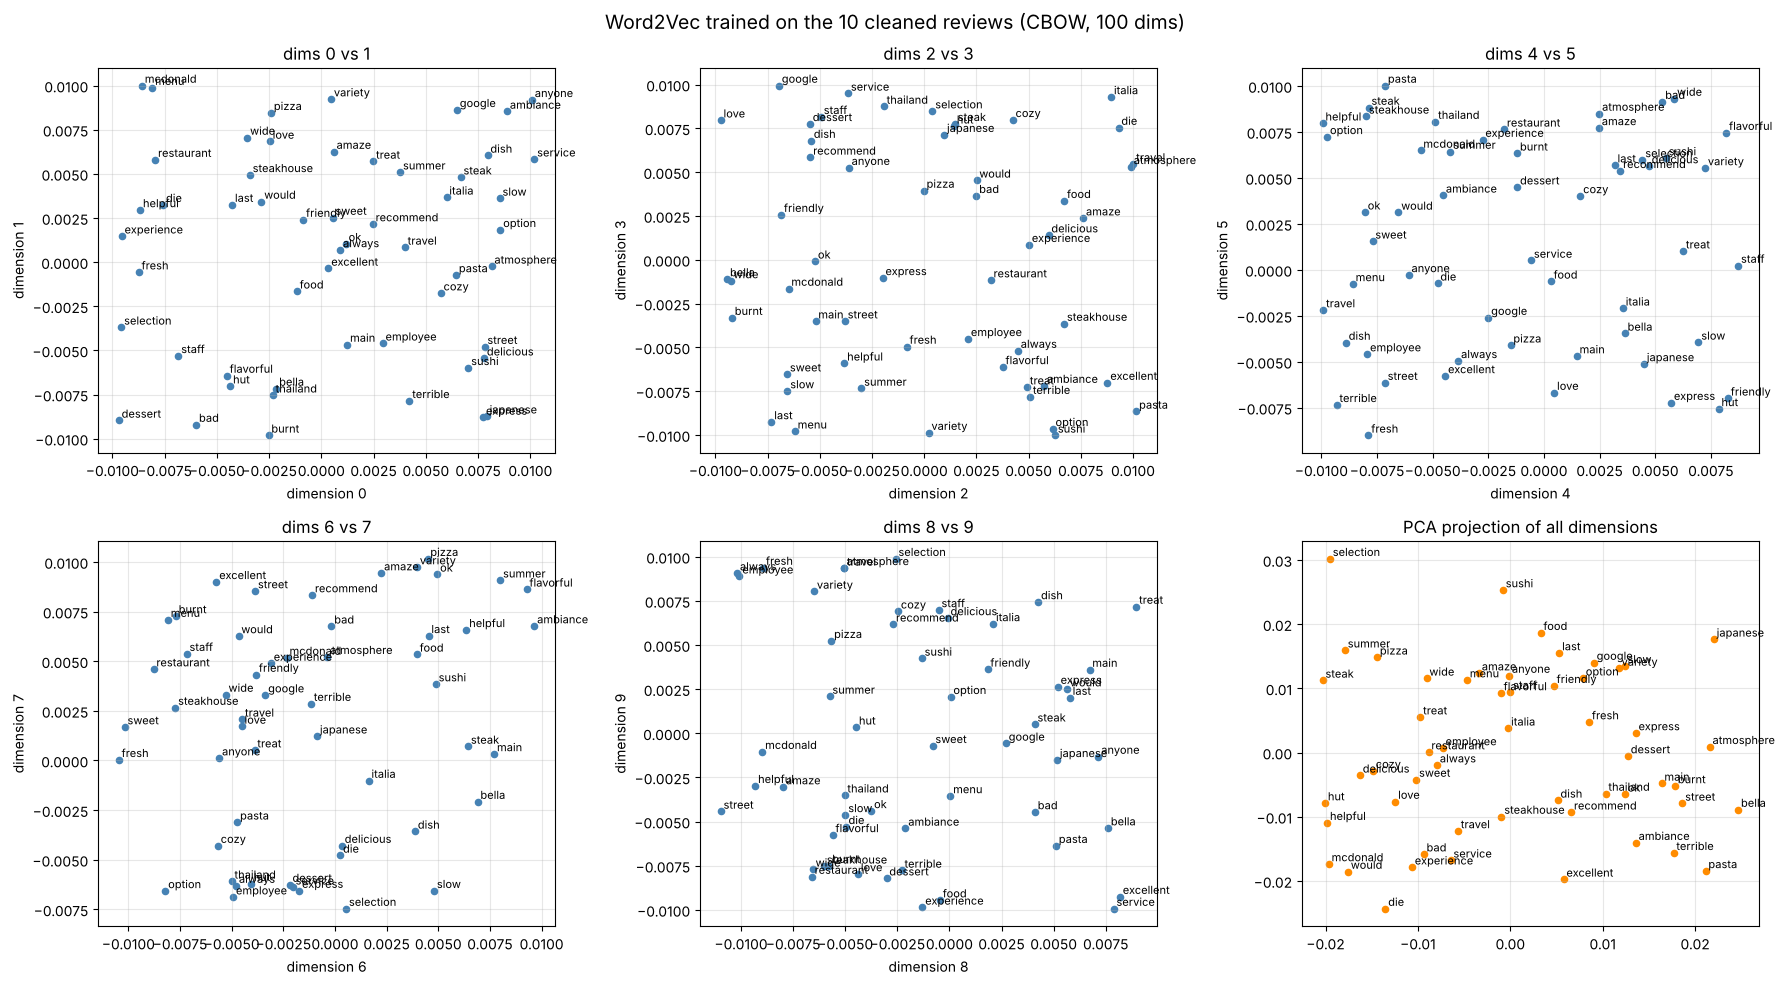

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def plot_word_embeddings(model, words=None, dim_pairs=((0, 1), (2, 3), (4, 5), (6, 7), (8, 9)), title=""):
    words = words or model.wv.index_to_key
    vectors = np.array([model.wv[w] for w in words])
    n_panels = len(dim_pairs) + 1
    ncols = 3
    nrows = int(np.ceil(n_panels / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows))
    axes = axes.ravel()

    for ax, (i, j) in zip(axes, dim_pairs):
        ax.scatter(vectors[:, i], vectors[:, j], s=20, color="steelblue")
        for k, w in enumerate(words):
            ax.annotate(w, (vectors[k, i], vectors[k, j]), fontsize=8, xytext=(2, 2), textcoords="offset points")
        ax.set_xlabel(f"dimension {i}"); ax.set_ylabel(f"dimension {j}")
        ax.set_title(f"dims {i} vs {j}"); ax.grid(True, alpha=0.3)

    ax = axes[len(dim_pairs)]
    pcs = PCA(n_components=2, random_state=0).fit_transform(vectors)
    ax.scatter(pcs[:, 0], pcs[:, 1], s=20, color="darkorange")
    for k, w in enumerate(words):
        ax.annotate(w, (pcs[k, 0], pcs[k, 1]), fontsize=8, xytext=(2, 2), textcoords="offset points")
    ax.set_title("PCA projection of all dimensions"); ax.grid(True, alpha=0.3)
    for ax in axes[n_panels:]:
        ax.axis("off")
    fig.suptitle(title or "Word2Vec embeddings", fontsize=14)
    plt.tight_layout(); plt.show()

plot_word_embeddings(w2v_model, title="Word2Vec trained on the 10 cleaned reviews (CBOW, 100 dims)")

In [17]:
# Are related words close?  cosine similarities between pairs we would expect to be related
def sim_table(model, pairs):
    return pd.DataFrame([(a, b, model.wv.similarity(a, b)) for a, b in pairs
                         if a in model.wv and b in model.wv],
                        columns=["word 1", "word 2", "cosine similarity"]).round(3)

pairs = [("pizza", "pasta"), ("sushi", "steak"), ("delicious", "flavorful"), ("terrible", "bad"),
         ("friendly", "helpful"), ("restaurant", "steakhouse"), ("pizza", "friendly"), ("service", "slow")]
display(sim_table(w2v_model, pairs))
for w in ["service", "pizza", "restaurant"]:
    print(w, "->", [(n, round(s, 3)) for n, s in w2v_model.wv.most_similar(w, topn=5)])

,word 1,word 2,cosine similarity
0,pizza,pasta,-0.174
1,sushi,steak,0.198
2,delicious,flavorful,0.118
3,terrible,bad,-0.118
4,friendly,helpful,-0.030
5,restaurant,steakhouse,0.163
6,pizza,friendly,0.060
7,service,slow,0.039


service -> [('delicious', 0.267), ('would', 0.167), ('love', 0.102), ('bella', 0.097), ('experience', 0.077)]
pizza -> [('wide', 0.202), ('menu', 0.18), ('selection', 0.17), ('fresh', 0.158), ('anyone', 0.141)]
restaurant -> [('flavorful', 0.231), ('staff', 0.215), ('selection', 0.204), ('street', 0.19), ('mcdonald', 0.189)]


### Analysis — are related words close to each other?
**No.** In every panel the points are scattered roughly uniformly over the range [-0.01, 0.01], and the PCA projection shows no structure either: `pizza` and `pasta`, `sushi` and `steak`, or `terrible` and `bad` are not neighbours.
The cosine similarities confirm this: `pizza–pasta` = **-0.17**, `terrible–bad` = **-0.12**, `friendly–helpful` = **-0.03**, while the unrelated pair `pizza–friendly` = **0.06**. The nearest neighbours are meaningless (`service → delicious, would, love`; `pizza → wide, menu, selection`).

**Possible reasons:**
1. **Far too little data.** Word2Vec learns from co-occurrences repeated across thousands of sentences. Here most words appear **once**, in a single 5–8-word sentence, so each word has one context and there is nothing to generalise from.
2. **Related words never share a context.** `pizza` and `pasta` are in different reviews, with different neighbours, so the model has no reason to bring them together. In this tiny corpus a word's neighbour is simply whatever happened to be in the same sentence.
3. **Too many dimensions for the data** (100 dims for 54 words): vectors barely move from their random initialisation (values about ±0.01).
4. **Plotting two raw dimensions out of 100** shows only 2 % of the information. PCA is better, but with noisy vectors it cannot reveal structure that does not exist.
5. **Preprocessing choices** removed context words and created artefacts (`amaze`, `die`, the lost `not`).

### 2.4 Go further
**a) Different preprocessing:** keep negations, and compare stemming vs lemmatization.

In [18]:
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()
negations = {"not", "no", "nor", "never"}

def preprocess_keep_negation(text, use_stemmer=False):
    tokens = [t for t in word_tokenize(text.lower()) if re.fullmatch(r"[a-z]+", t) or t == "n't"]
    tokens = ["not" if t == "n't" else t for t in tokens]
    tokens = [t for t in tokens if t not in stop_words or t in negations]
    if use_stemmer:
        return " ".join(stemmer.stem(t) for t in tokens)
    return " ".join(lemmatizer.lemmatize(t, penn_to_wordnet(tag)) for t, tag in pos_tag(tokens))

pd.DataFrame({
    "lemmatized (exercise)": cleaned_reviews,
    "lemmatized + negations": [preprocess_keep_negation(r) for r in raw_reviews],
    "stemmed + negations": [preprocess_keep_negation(r, use_stemmer=True) for r in raw_reviews],
})

,lemmatized (exercise),lemmatized + negations,stemmed + negations
0,mcdonald food ok service bad,mcdonald food ok service bad,mcdonald food ok servic bad
1,would recommend japanese restaurant anyone,would not recommend japanese restaurant anyone,would not recommend japanes restaur anyon
2,love restaurant travel thailand last summer,love restaurant travel thailand last summer,love restaur travel thailand last summer
3,menu love wide variety option,menu love wide variety option,menu love wide varieti option
4,staff friendly helpful google employee restaurant,staff friendly helpful google employee restaurant,staff friendli help googl employe restaur
5,ambiance bella italia amaze pasta dish delicious,ambiance bella italia amaze pasta dish delicious,ambianc bella italia amaz pasta dish delici
6,terrible experience pizza hut pizza burnt service slow,terrible experience pizza hut pizza burnt service slow,terribl experi pizza hut pizza burnt servic slow
7,sushi sushi express always fresh flavorful,sushi sushi express always fresh flavorful,sushi sushi express alway fresh flavor
8,steakhouse main street cozy atmosphere excellent steak,steakhouse main street cozy atmosphere excellent steak,steakhous main street cozi atmospher excel steak
9,dessert selection sweet treat die,dessert selection sweet treat die,dessert select sweet treat die


**b) Tuning Word2Vec:** with only ~60 words, 100 dimensions is far too many. We compare a smaller skip-gram model (`vector_size=10`, `sg=1`, `window=3`, many epochs). The question is whether the neighbourhoods become more meaningful, and whether this is stable across random seeds.

In [19]:
pairs_related = [("pizza", "pasta"), ("delicious", "flavorful"), ("terrible", "bad"),
                 ("friendly", "helpful"), ("sushi", "fresh"), ("steak", "steakhouse")]
pairs_unrelated = [("pizza", "friendly"), ("sushi", "thailand"), ("dessert", "slow"),
                   ("menu", "burnt"), ("staff", "pasta"), ("ambiance", "summer")]

def related_gap(model):
    rel = np.mean([model.wv.similarity(a, b) for a, b in pairs_related])
    unrel = np.mean([model.wv.similarity(a, b) for a, b in pairs_unrelated])
    return rel, unrel

configs = {
    "CBOW, 100d, win5, 100ep": dict(vector_size=100, window=5, sg=0, epochs=100),
    "CBOW, 10d,  win3, 300ep": dict(vector_size=10, window=3, sg=0, epochs=300),
    "Skip-gram, 10d, win3, 300ep": dict(vector_size=10, window=3, sg=1, epochs=300),
    "Skip-gram, 10d, win3, 300ep, neg=10": dict(vector_size=10, window=3, sg=1, epochs=300, negative=10),
}
rows = []
for name, cfg in configs.items():
    for seed in range(5):
        m = Word2Vec(tokenized_reviews, min_count=1, workers=1, seed=seed, **cfg)
        rel, unrel = related_gap(m)
        rows.append({"config": name, "seed": seed, "related": rel, "unrelated": unrel, "gap": rel - unrel})
tune = pd.DataFrame(rows)
display(tune.groupby("config")[["related", "unrelated", "gap"]].agg(["mean", "std"]).round(3))

related        unrelated           gap  \
                                       mean    std      mean    std   mean   
config                                                                       
CBOW, 100d, win5, 100ep               0.049  0.050    -0.019  0.019  0.068   
CBOW, 10d,  win3, 300ep               0.490  0.088     0.370  0.270  0.120   
Skip-gram, 10d, win3, 300ep           0.744  0.106     0.633  0.251  0.110   
Skip-gram, 10d, win3, 300ep, neg=10   0.984  0.002     0.978  0.008  0.006   

                                            
                                       std  
config                                      
CBOW, 100d, win5, 100ep              0.046  
CBOW, 10d,  win3, 300ep              0.199  
Skip-gram, 10d, win3, 300ep          0.149  
Skip-gram, 10d, win3, 300ep, neg=10  0.007

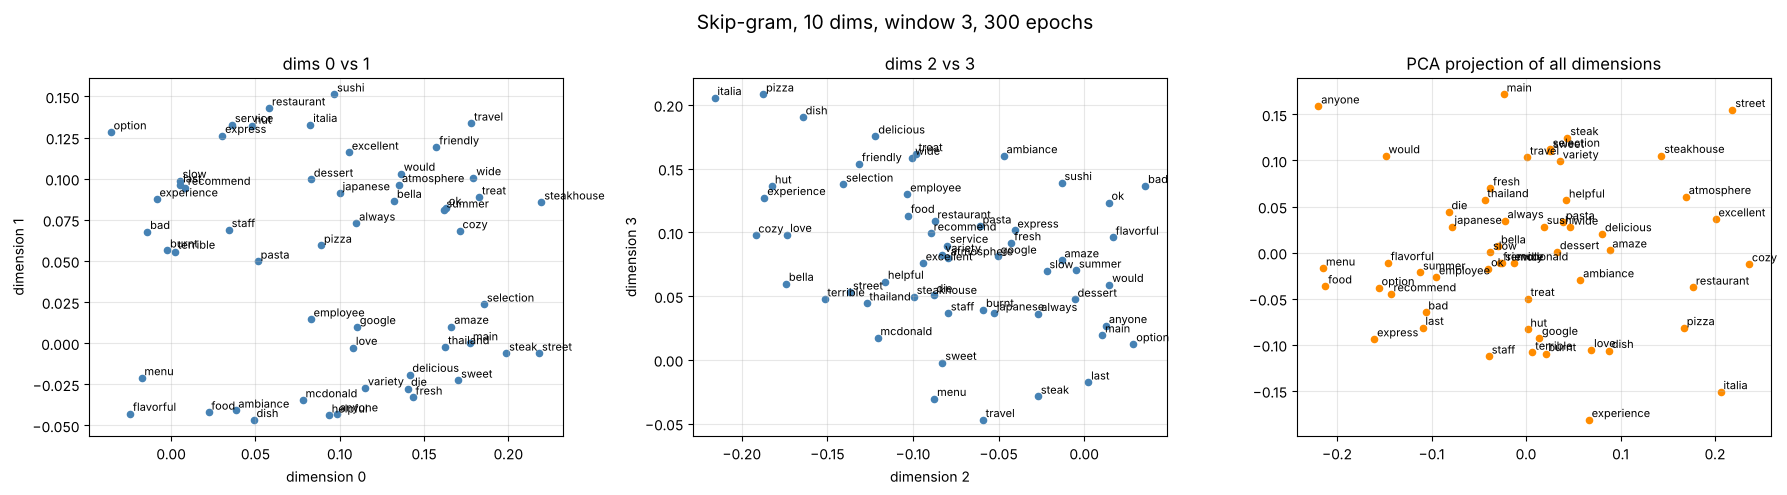

In [20]:
w2v_small = Word2Vec(tokenized_reviews, vector_size=10, window=3, sg=1, epochs=300, min_count=1, workers=1, seed=42)
plot_word_embeddings(w2v_small, dim_pairs=((0, 1), (2, 3)), title="Skip-gram, 10 dims, window 3, 300 epochs")

**c) Advanced visualisation + more data:** embeddings only become meaningful with lots of text. We load pre-trained **GloVe** vectors (50 dims, trained on 6 B tokens of Wikipedia + Gigaword) through `gensim.downloader` and project the same vocabulary with **t-SNE**, coloured by a manual semantic category.

GloVe vocabulary: 400000 words x 50 dims


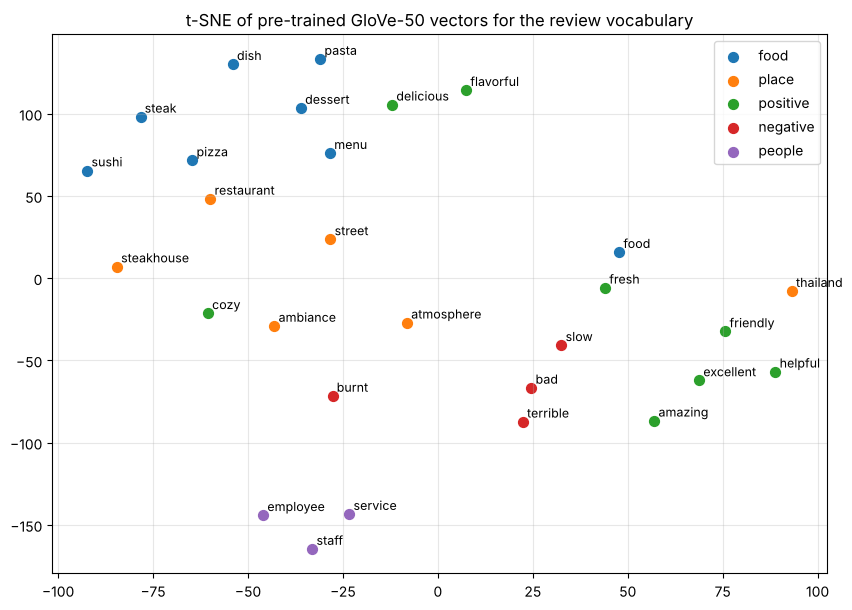

,word 1,word 2,cosine (GloVe)
0,pizza,pasta,0.735
1,delicious,flavorful,0.831
2,terrible,bad,0.777
3,friendly,helpful,0.611
4,sushi,fresh,0.318
5,steak,steakhouse,0.475
6,pizza,friendly,0.306
7,sushi,thailand,0.146
8,dessert,slow,0.257
9,menu,burnt,-0.004



GloVe related mean: 0.625 | unrelated mean: 0.148


In [21]:
import gensim.downloader as api
from sklearn.manifold import TSNE

import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):   # hide the long download progress bar
    glove = api.load("glove-wiki-gigaword-50")
print("GloVe vocabulary:", len(glove.index_to_key), "words x", glove.vector_size, "dims")

categories = {
    "food": ["food", "pizza", "pasta", "sushi", "steak", "dessert", "dish", "menu"],
    "place": ["restaurant", "steakhouse", "street", "thailand", "atmosphere", "ambiance"],
    "positive": ["delicious", "amazing", "excellent", "friendly", "helpful", "fresh", "cozy", "flavorful"],
    "negative": ["terrible", "bad", "burnt", "slow"],
    "people": ["staff", "employee", "service"],
}
words, cats = [], []
for c, ws in categories.items():
    for w in ws:
        if w in glove:
            words.append(w); cats.append(c)
vecs = np.array([glove[w] for w in words])

xy = TSNE(n_components=2, perplexity=8, random_state=42, init="pca").fit_transform(vecs)
colors = dict(zip(categories, plt.cm.tab10.colors))
plt.figure(figsize=(10, 7))
for c in categories:
    idx = [i for i, cc in enumerate(cats) if cc == c]
    plt.scatter(xy[idx, 0], xy[idx, 1], s=50, color=colors[c], label=c)
for i, w in enumerate(words):
    plt.annotate(w, xy[i], fontsize=9, xytext=(3, 3), textcoords="offset points")
plt.legend(); plt.title("t-SNE of pre-trained GloVe-50 vectors for the review vocabulary"); plt.grid(alpha=0.3)
plt.show()

display(pd.DataFrame([(a, b, glove.similarity(a, b)) for a, b in pairs_related + pairs_unrelated
                                   if a in glove and b in glove], columns=["word 1", "word 2", "cosine (GloVe)"]).round(3))
print("\nGloVe related mean:", round(np.mean([glove.similarity(a, b) for a, b in pairs_related]), 3),
      "| unrelated mean:", round(np.mean([glove.similarity(a, b) for a, b in pairs_unrelated]), 3))

### Analysis — going further
**Preprocessing.** Keeping negations (`would **not** recommend…`) preserves the meaning of review 2. The Porter stemmer is cruder than the lemmatizer: it produces non-words (`restaur`, `servic`, `delici`, `friendli`, `googl`) and merges words by chopping suffixes (`flavorful → flavor`, `selection → select`). Its advantage is that it does not need POS tags. For embeddings or display, lemmatization gives cleaner tokens.

**Tuning Word2Vec (5 seeds per configuration).** "related" and "unrelated" are the mean cosine similarity of 6 related pairs (pizza–pasta, terrible–bad, …) and 6 unrelated pairs.
- The default 100-d CBOW model gives about 0 everywhere (0.049 vs -0.019): this is noise.
- Smaller vectors (10 dims) with more epochs push **all** similarities up (CBOW 0.49 vs 0.37; skip-gram 0.74 vs 0.63). The gap between related and unrelated pairs (≈ 0.11–0.12) is smaller than its standard deviation across seeds (0.15–0.20), so it is not reliable.
- With `negative=10`, every word becomes almost identical (0.98 for both groups): the vectors collapse because the model overfits a corpus far too small for this many updates.
- Conclusion: **no hyper-parameter setting can create semantic structure from 10 sentences.** Tuning only changes how the noise looks.

**More data + t-SNE.** The pre-trained GloVe vectors (trained on 6 billion tokens) separate related from unrelated pairs clearly: mean similarity **0.625 vs 0.148** (`delicious–flavorful` 0.83, `terrible–bad` 0.78, `pizza–pasta` 0.74, `menu–burnt` ≈ 0). The t-SNE plot shows meaningful groups:
- **foods** together (sushi, steak, pizza, pasta, dish, dessert, menu);
- **places** together (restaurant, steakhouse, street, ambiance, atmosphere);
- **people** together (staff, employee, service);
- the **negative adjectives** close to each other (bad, terrible, slow, burnt);
- the **positive adjectives** close to each other (excellent, amazing, friendly, helpful).

This is the answer to the question above: Word2Vec does capture "related words are close", **but only with a large corpus**. For a small dataset, use pre-trained embeddings (GloVe, fastText, or Word2Vec trained on Google News) or fine-tune them, rather than training from scratch.